 This section imports the Python libraries needed for data manipulation, visualization, statistical analysis, and modeling. Pandas and NumPy are used for working with data, while Matplotlib and Seaborn are used to create visualizations.

In [759]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

 These libraries were imported succesfully and are now available for the analysis

This section loads the EdGap dataset and the CCD school information dataset. The EdGap dataset contains ACT scores and socioeconomic characteristics, while the CCD dataset provides additional information about each school, including state, school type, school level, and charter status.

In [760]:
edgap = pd.read_excel('/Users/hakimmacbook/Desktop/Foundations of Data Science 5100/Education/Data/EdGap_data.xlsx',
                      dtype={'NCESSCH School ID': object}
                     )

    

/opt/anaconda3/lib/python3.14/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


In [761]:
school_information = pd.read_csv(
    '/Users/hakimmacbook/Desktop/Foundations of Data Science 5100/Education/Data/ccd_sch_029_1617_w_1a_11212017.csv',
    encoding='unicode_escape',
    low_memory=False
)

In [764]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


The first few rows confirm that both datasets loaded successfully. The EdGap dataset contains school-level socioeconomic and ACT information, while the CCD dataset contains school identification and classification information that can later be merged with EdGap.

In [765]:
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


In [766]:
pd.set_option('display.max_columns', None)
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,01,NaN,AL-210,0100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


This code examines the structure of the EdGap dataset, including the number of observations, variable names, data types, and the number of non-missing values in each column.

In [767]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


The EdGap dataset contains 7986 schools and 7 variables. Most variables have nearly complete data, although several socioeconomic variables contain a small number of missing observations

This pairplot visualization shows the distributions and pairwise relationships within numerical variables in the EdGap data. The scatterplots make it possible to identifiy any possible trends, correlations or interesting observations

In [768]:
sns.pairplot(
    edgap.drop(columns="id")
);
plt.show

KeyError: "['id'] not found in axis"

The pairplot shows socioecomic variables seem to be related to one another and to average ACT scores. In particular, variables associated with higher socioeconomic status appear to have different relationship with test scores than mesures of economic disadvantage.

The second pairplot shows relationship between average test scores and socioeconomic predictor variables. The code implements regression lines to make direction of each relationship easier to see

In [770]:
fig = sns.pairplot(
    edgap.drop(columns=("id"),
    kind="reg",
    plot_kws={
        "line_kws": {"color": "blue"},
        "scatter_kws": {"alpha": 0.5, "color": "k", "s": 7},
    },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == "CT Median Household Income":
        ax.ticklabel_format(
            style="sci",
            axis="x",
            scilimits=(0, 0)
        )

    ax.set_xlabel(
        ax.get_xlabel(),
        fontsize=8,
        rotation=30,
        ha="right"
    )

    ax.set_ylabel(
        ax.get_ylabel(),
        fontsize=8
    )

    plt.setp(
        ax.get_xticklabels(),
        rotation=30,
        ha="right"
    )

plt.show()


SyntaxError: '(' was never closed (250821462.py, line 1)

Plot suggests that avg scores are positively related to some measure of advantage such as the variables examined such as college education income, while variables such as unemployement and free/reduced lunch appear to have negative relationship with scores.

Code below isolates the y variable avg act into one row to be able to examine closely

In [772]:
fig = sns.pairplot(
    edgap.drop(columns=("id"),
    y_vars=['average_act'],
    kind="reg",
    plot_kws={
        "line_kws": {"color": "blue"},
        "scatter_kws": {"alpha": 0.5, "color": "k", "s": 7},
    },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == "CT Median Household Income":
        ax.ticklabel_format(
            style="sci",
            axis="x",
            scilimits=(0, 0)
        )

    ax.set_xlabel(
        ax.get_xlabel(),
        fontsize=8,
        rotation=30,
        ha="right"
    )

    ax.set_ylabel(
        ax.get_ylabel(),
        fontsize=8
    )

    plt.setp(
        ax.get_xticklabels(),
        rotation=30,
        ha="right"
    )

plt.show()

SyntaxError: '(' was never closed (3611203293.py, line 1)

Code below selects variables that we need analysis for 

In [773]:
school_information = school_information[
    [
        'SCHOOL_YEAR',
        'NCESSCH',
        'LSTATE',
        'LZIP',
        'SCH_TYPE_TEXT',
        'LEVEL',
        'CHARTER_TEXT'
    ]
]

In [774]:
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,CHARTER_TEXT
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


The code shows the columns and variable types we are examining

Codes below rename the variables to shorter more readable names 

In [775]:
edgap = edgap.rename(
    columns={
        "NCESSCH School ID": "id",
        "CT Pct Adults with College Degree": "percent_college",
        "CT Unemployment Rate": "rate_unemployment",
        "CT Pct Childre In Married Couple Family": "percent_married",
        "CT Median Household Income": "median_income",
        "School ACT average (or equivalent if SAT score)": "average_act",
        "School Pct Free and Reduced Lunch": "percent_lunch",
    }
)

In [776]:
school_information = school_information.rename(
    columns={
        "SCHOOL_YEAR": "year",
        "NCESSCH": "id",
        "LSTATE": "state",
        "LZIP": "zip_code",
        "SCH_TYPE_TEXT": "school_type",
        "LEVEL": "school_level",
        "CHARTER_TEXT": "charter"
    }
)

In [777]:
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [778]:
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


The data set now contains consistent easier to read/use variable names. 

Code below treats values in the id colum like objects instead of numbers

In [779]:
school_information['id'] = school_information['id'].astype('object')

In [780]:
school_information.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          102183 non-null  str   
 1   id            102181 non-null  object
 2   state         102183 non-null  str   
 3   zip_code      102183 non-null  str   
 4   school_type   102181 non-null  str   
 5   school_level  102179 non-null  str   
 6   charter       102179 non-null  str   
dtypes: object(1), str(6)
memory usage: 9.5+ MB


The EdGap and CCD datasets are merged using the school id numbers. a left join is used so the schools in the ed gap data are retained.

In [781]:
df = edgap.merge(
    school_information,
    how='left',
    on='id'
)

The code works to merge the dataset to be able to utilize

In [782]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


In [783]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   str    
 8   state              7898 non-null   str    
 9   zip_code           7898 non-null   str    
 10  school_type        7898 non-null   str    
 11  school_level       7898 non-null   str    
 12  charter            7898 non-null   str    
dtypes: float64(6), object(1), str(6)
memory usage: 1.1+ MB


Descripitve stats are used to examine ranges, averages, and variability of numerical values

In [784]:
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


In [785]:
df.select_dtypes(include=['number']).agg(['min','max']).round(2)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


The summary shows values in 2 variables some free/reduced lunch proportions were below zero, and some act scores below 1.They are treated as missing values?

In [786]:
df.loc[df['percent_lunch'] < 0, 'percent_lunch'] = np.nan
df.loc[df['average_act'] < 1, 'average_act'] = np.nan

Invalid values for reduced lunch participation and act scores were replaced with NaN so they can be handled during the missing data cleaning process

I used this code to verify if all my values were being populated using .shape

In [787]:
test_merge = edgap.merge(
    school_information,
    how='inner',
    on='id'
)

print(test_merge.shape)

(7898, 13)


It worked!

Counts were used to examine types and characterstics of schools in the merged data

In [788]:
df['school_type'].value_counts()

school_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [789]:
df['school_level'].value_counts()

school_level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64

In [790]:
df['charter'].value_counts()

charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64

Most schools in the data are regular schools. Majority classified as HS and most are non-charter schools. The analysis focuses on highschools and act performance, data is restricted to schools classified as High.

In [791]:
df = df.loc[df['school_level'] == 'High']

7230 observations remain for the analysis

the cleaned data set is checked for duplicate records and missing values to determine if we need more additional cleaning before the next steps.

In [792]:
df.duplicated().sum()

np.int64(0)

no duplicates

In [793]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


missing values among the socioecononomic variables. proportions of missing observations are small.

In [794]:
percent_missing = df.isna().mean().round(4) *100

In [795]:
percent_missing = df.isna().sum() / len(df) * 100
percent_missing.to_frame(name='Percent Missing Values')

,Percent Missing Values
id,0.000000
rate_unemployment,0.165975
percent_college,0.152144
percent_married,0.276625
median_income,0.221300
average_act,0.041494
percent_lunch,0.276625
year,0.000000
state,0.000000
zip_code,0.000000


In [796]:
df.isna().sum()

id                    0
rate_unemployment    12
percent_college      11
percent_married      20
median_income        16
average_act           3
percent_lunch        20
year                  0
state                 0
zip_code              0
school_type           0
school_level          0
charter               0
dtype: int64

In [797]:
print(df.shape)

(7230, 13)


In [798]:
df = edgap.merge(
    school_information,
    how='left',
    on='id'
)

In [799]:
print(df.shape)

(7986, 13)


In [800]:
df['school_type'].value_counts(dropna=False)

school_type
Regular School                 7885
NaN                              88
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [801]:
print(df.shape)

(7986, 13)


In [802]:
df['state'].value_counts()

state
TX    966
OH    693
PA    601
IL    590
MI    587
FL    441
NC    416
WI    386
NY    385
GA    383
NJ    354
MO    350
IN    347
TN    309
MA    292
WA    273
LA    245
KY    216
WY     38
DE     26
Name: count, dtype: int64

In [803]:
df['state'].value_counts(dropna=False)

state
TX     966
OH     693
PA     601
IL     590
MI     587
FL     441
NC     416
WI     386
NY     385
GA     383
NJ     354
MO     350
IN     347
TN     309
MA     292
WA     273
LA     245
KY     216
NaN     88
WY      38
DE      26
Name: count, dtype: int64

In [804]:
print(df.shape)

(7986, 13)


In [805]:
school_information['state'].value_counts().head()

state
CA    10408
TX     9474
NY     4869
FL     4419
IL     4216
Name: count, dtype: int64

In [806]:
print("EdGap rows:", len(edgap))
print("School information rows:", len(school_information))

matches = edgap['id'].isin(school_information['id'])
print("Number matched:", matches.sum())

EdGap rows: 7986
School information rows: 102183
Number matched: 7898


In [807]:
df = df.dropna(
    subset=[
        'year',
        'state',
        'zip_code',
        'school_type',
        'school_level',
        'charter'
    ]
)

In [808]:
df = edgap.merge(
    school_information,
    how='left',
    on='id'
)

displays number of schools represented in data set by state. the visualization helps show geographic distribution of the samples and whether some states are more represented than other states. Could dig deeper here and see if regional differences affect scores

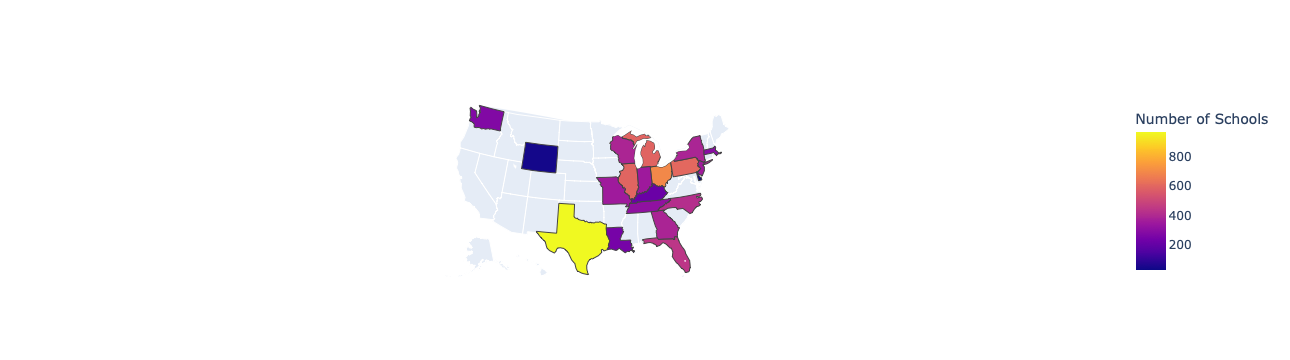

In [809]:
import plotly.graph_objs as pg
import plotly.offline as po

layout = dict(
    geo={"scope": "usa"},
    coloraxis_colorbar=dict(title="Number of Schools")
)

data = dict(
    type="choropleth",
    locations=df["state"].value_counts().index,
    locationmode="USA-states",
    z=df["state"].value_counts().values,
    coloraxis="coloraxis",
)

x = pg.Figure(
    data=[data],
    layout=layout
)

po.iplot(x)

In [810]:
df=df.dropna(subset=['average_act'])

Map shows number of schools varies across states. 

to double check missing values

In [811]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,14
percent_college,13
percent_married,25
median_income,20
average_act,0
percent_lunch,0
year,88
state,88
zip_code,88


Predictor variables are used in the analysis includes the variables below. predictors with missing values will be imputed using iterative imputation so that observations do not have to be discarded.

In [812]:
predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'state',
    'charter'
]

In [813]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [814]:
imputer = IterativeImputer()

In [815]:
numerical_predictors = df[predictor_variables].select_dtypes(include='number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


In [816]:
imputer.fit(df.loc[:, numerical_predictors])

,"estimator estimator: estimator object, default=BayesianRidge()The estimator to use at each step of the round-robin imputation.If `sample_posterior=True`, the estimator must support`return_std` in its `predict` method.",None
,"missing_values missing_values: int or np.nan, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to `np.nan`, since `pd.NA` will be converted to `np.nan`.",nan
,"sample_posterior sample_posterior: bool, default=FalseWhether to sample from the (Gaussian) predictive posterior of thefitted estimator for each imputation. Estimator must support`return_std` in its `predict` method if set to `True`. Set to`True` if using `IterativeImputer` for multiple imputations.",False
,"max_iter max_iter: int, default=10Maximum number of imputation rounds to perform before returning theimputations computed during the final round. A round is a singleimputation of each feature with missing values. The stopping criterionis met once `max(abs(X_t - X_{t-1}))/max(abs(X[known_vals])) < tol`,where `X_t` is `X` at iteration `t`. Note that early stopping is onlyapplied if `sample_posterior=False`.",10
,"tol tol: float, default=1e-3Tolerance of the stopping condition.",0.001
,"n_nearest_features n_nearest_features: int, default=NoneNumber of other features to use to estimate the missing values ofeach feature column. Nearness between features is measured usingthe absolute correlation coefficient between each feature pair (afterinitial imputation). To ensure coverage of features throughout theimputation process, the neighbor features are not necessarily nearest,but are drawn with probability proportional to correlation for eachimputed target feature. Can provide significant speed-up when thenumber of features is huge. If `None`, all features will be used.",None
,"initial_strategy initial_strategy: {'mean', 'median', 'most_frequent', 'constant'}, default='mean'Which strategy to use to initialize the missing values. Same as the`strategy` parameter in :class:`~sklearn.impute.SimpleImputer`.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen `strategy=""constant""`, `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types... versionadded:: 1.3",None
,"imputation_order imputation_order: {'ascending', 'descending', 'roman', 'arabic', 'random'}, default='ascending'The order in which the features will be imputed. Possible values:- `'ascending'`: From features with fewest missing values to most.- `'descending'`: From features with most missing values to fewest.- `'roman'`: Left to right.- `'arabic'`: Right to left.- `'random'`: A random order for each round.",'ascending'
,"skip_complete skip_complete: bool, default=FalseIf `True` then features with missing values during :meth:`transform`which did not have any missing values during :meth:`fit` will beimputed with the initial imputation method only. Set to `True` if youhave many features with no missing values at both :meth:`fit` and:meth:`transform` time to save compute.",False
,"min_value min_value: float or array-like of shape (n_features,), default=-np.infMinimum possible imputed value. Broadcast to shape `(n_features,)` ifscalar. If array-like, expects shape `(n_features,)`, one min value foreach feature. The default is `-np.inf`... versionchanged:: 0.23 Added support for array-like.",-inf


In [817]:
df.loc[:,numerical_predictors] = imputer.transform(df.loc[:, numerical_predictors])

After imputation, the selected numerical predictors no longer contain missing values, allowing them to be used in the subsequent exploratory and regression analyses.

In [818]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,88
state,88
zip_code,88


In [819]:
print(edgap.columns.tolist())
print(school_information.columns.tolist())

['id', 'rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'average_act', 'percent_lunch']
['year', 'id', 'state', 'zip_code', 'school_type', 'school_level', 'charter']


In [820]:
edgap = edgap.rename(
    columns={
        "NCESSCH School ID": "id",
        "CT Unemployment Rate": "rate_unemployment",
        "CT Pct Adults with College Degree": "percent_college",
        "CT Pct Childre In Married Couple Family": "percent_married",
        "CT Median Household Income": "median_income",
        "School ACT average (or equivalent if SAT score)": "average_act",
        "School Pct Free and Reduced Lunch": "percent_lunch",
    }
)

saved as csv file so data cleaning does not have to be repeated in analysis and modeling

In [821]:
df.to_csv(
    'education_clean.csv',
    encoding='utf-8-sig',
    index=False
)

In [822]:
import os
print(os.getcwd())

/Users/hakimmacbook/Desktop/Foundations of Data Science 5100/Education/Code


Cleaned data set successfully saved

In [823]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
sns.set_style("whitegrid")

from sklearn.preprocessing import StandardScaler

import statsmodels.formula.api as smf
import statsmodels.api as sm

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

In [824]:
df = pd.read_csv('/Users/hakimmacbook/Desktop/Foundations of Data Science 5100/Education/Code/education_clean.csv'
                )

In [825]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804.0,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709.0,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709.0,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958.0,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934.0,Regular School,High,No


## Exploratory Data Analysis

# Examining distributions and relationships

The code below produces a correlation matrix. it examines direction of the linear relationship. helps identify what predictors are most associaeted with act performance. and whether predictors are highly correlated.

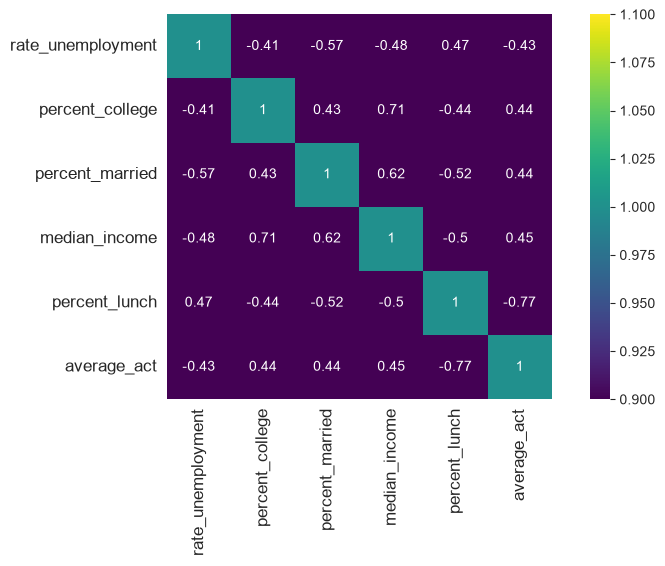

In [826]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']
numerical_predictors = df[predictor_variables].select_dtypes(include='number').columns.to_list()

corr_matrix = df[numerical_predictors + ["average_act"]].corr()

plt.figure(figsize=(10,5))

sns.heatmap(
    corr_matrix, vmax=1, vmin=1, square=True, annot=True, cmap="viridis"
)
plt.tick_params(labelsize=12)

plt.show()


The matrix shows the strong positive relationships. Several socioecomic predicators seem to be correlated w/ one another, suggesting variables may reprenesnt relation of socioeconomic conditions.

This pairplot examines the relationships among the socioeconomic predictors and average ACT score while distinguishing schools by charter status.

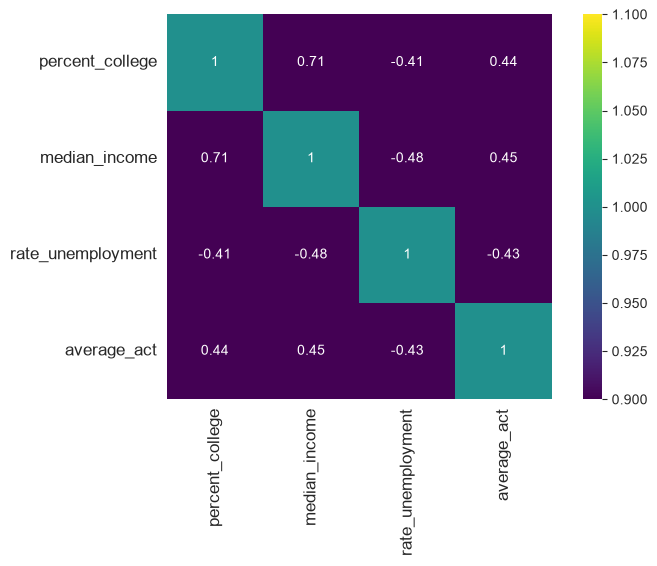

In [827]:
predictor_variables = [
    'percent_college',
    'median_income',
    'rate_unemployment'
]

numerical_predictors = (
    df[predictor_variables]
    .select_dtypes(include='number')
    .columns
    .to_list()
)

corr_matrix = df[
    numerical_predictors + ['average_act']
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    corr_matrix,
    vmax=1,
    vmin=1,
    square=True,
    annot=True,
    cmap='viridis'
)

plt.tick_params(labelsize=12)

plt.show()

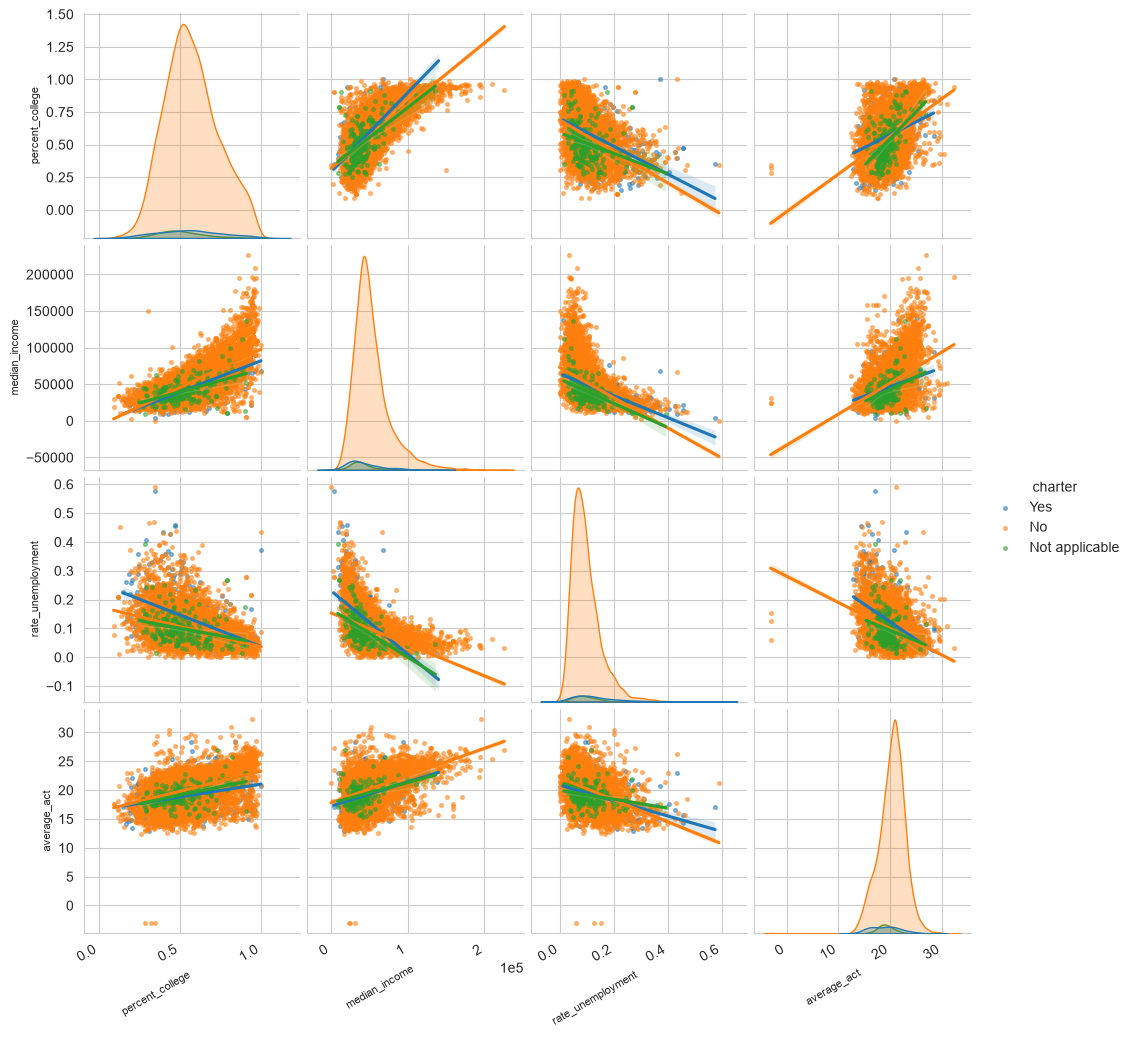

In [828]:
fig = sns.pairplot(
    data=df,
    vars=numerical_predictors + ['average_act'],
    hue='charter',
    kind='reg',
    plot_kws={
        'scatter_kws': {'alpha': 0.5, 's': 7}
    }
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'median_income':
        ax.ticklabel_format(
            style='sci',
            axis='x',
            scilimits=(0, 0)
        )

    ax.set_xlabel(
        ax.get_xlabel(),
        fontsize=8,
        rotation=30,
        ha='right'
    )

    ax.set_ylabel(
        ax.get_ylabel(),
        fontsize=8
    )

    plt.setp(
        ax.get_xticklabels(),
        rotation=30,
        ha='right'
    )

plt.show()

Regression lines help visualize overall trends, while the color groups make it possible to compare patterns between charter and non-charter schools.

Code below creates box plot comparing distribution of numerical predictor variables except median income

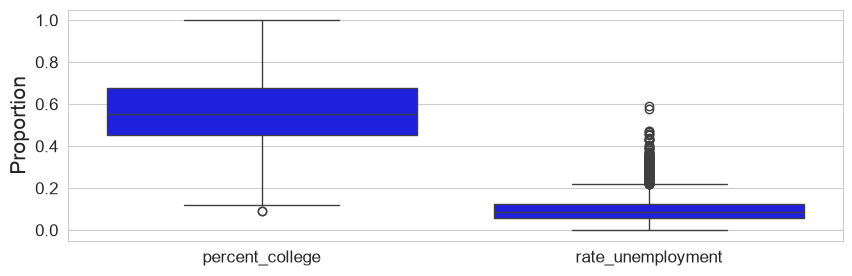

In [829]:
plt.figure(figsize=(10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data=df[fractions], color='b')

plt.ylabel('Proportion', fontsize=15)

plt.tick_params(labelsize=12)

plt.show()

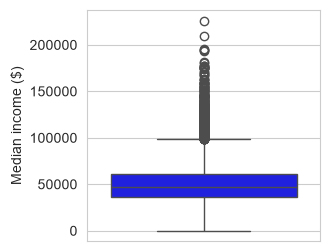

In [830]:
plt.figure(figsize=(3,3))

sns.boxplot(data=df, y='median_income', color='b')

plt.ylabel('Median income ($)')

plt.show()

The plots show differences in distributions and variability of socioeconomic predictions.

In [831]:
[col for col in school_information.columns
 if 'URBAN' in col.upper() or 'RURAL' in col.upper() or 'LOCALE' in col.upper()]

[]

In [832]:
model = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch',
    data=df
).fit()

In [833]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.609
Model:                            OLS   Adj. R-squared:                  0.609
Method:                 Least Squares   F-statistic:                     2484.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:23:41   Log-Likelihood:                -15199.
No. Observations:                7986   AIC:                         3.041e+04
Df Residuals:                    7980   BIC:                         3.045e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.5466      0.13

 Overall, the results suggest that unemployment, adult college education, and free/reduced lunch participation are significant predictors of average ACT scores in this model, while married-couple family percentage and median household income are not significant after controlling for the other variables.

In [834]:
y_hat = model.predict()

In [835]:
model_personal = smf.ols(
    formula='average_act ~ percent_college + median_income + rate_unemployment',
    data=df
).fit()

In [836]:
y_hat_personal = model_personal.predict()

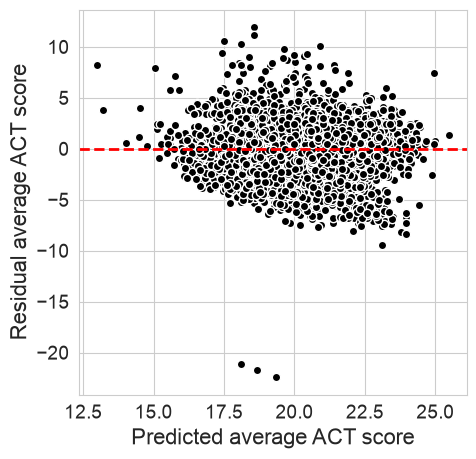

In [837]:
plt.figure(figsize=(5, 5))

plt.plot(
    y_hat_personal,
    model_personal.resid,
    'ko',
    mec='w'
)

plt.axhline(
    0,
    color='r',
    linestyle='dashed',
    lw=2
)

plt.xlabel(
    'Predicted average ACT score',
    fontsize=16
)

plt.ylabel(
    'Residual average ACT score',
    fontsize=16
)

plt.tick_params(labelsize=14)

plt.show()

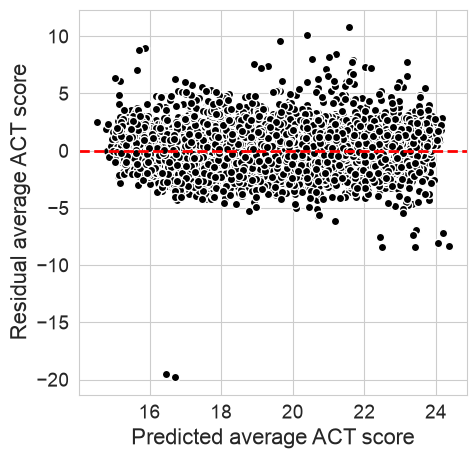

In [838]:
plt.figure(figsize=(5, 5))

plt.plot(y_hat, model.resid, 'ko', mec='w')

plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

In [839]:
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.609
Model:                            OLS   Adj. R-squared:                  0.609
Method:                 Least Squares   F-statistic:                     4141.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:23:43   Log-Likelihood:                -15199.
No. Observations:                7986   AIC:                         3.041e+04
Df Residuals:                    7982   BIC:                         3.043e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6031      0.10

he reduced model performs about as well as the full model while using fewer predictors. This suggests that unemployment rate, college education, and free/reduced lunch participation capture most of the predictive information in the original model.

In [840]:
import statsmodels.formula.api as smf

In [841]:
model_reduced = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_lunch',
    data=df
).fit()

In [842]:
y_hat = model_reduced.predict()

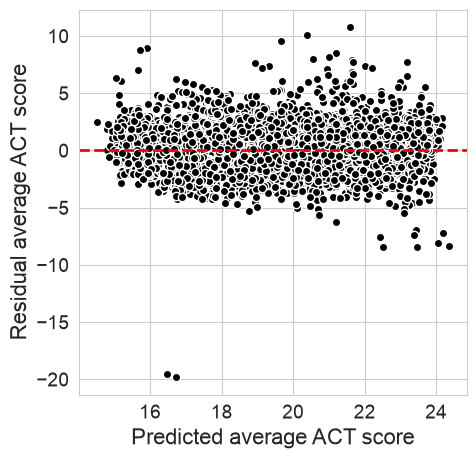

In [843]:
plt.figure(figsize=(5, 5))

plt.plot(y_hat, model_reduced.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

This residual plot is used to evaluate how well the regression model fits the data. The predicted average ACT scores are plotted on the x-axis and the residuals, or prediction errors, are plotted on the y-axis. A well-fitting linear model should have residuals scattered around zero without a clear pattern.

In [844]:
mean_absolute_error(df['average_act'], model_reduced.predict())

1.184459940119773

In [845]:
anova_lm(model_reduced,model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7982.0,21036.175159,0.0,NaN,NaN,NaN
1,7980.0,21035.130506,2.0,1.044653,0.198153,0.820249


In [846]:
from sklearn.preprocessing import StandardScaler

predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch'
]

scaled_columns = [
    var + '_normalized'
    for var in predictor_variables
]

print(scaled_columns)

scaler = StandardScaler().fit(
    df[predictor_variables]
)

df[scaled_columns] = scaler.transform(
    df[predictor_variables]
)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_married_normalized', 'median_income_normalized', 'percent_lunch_normalized']


In [847]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

In [848]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_married_normalized,median_income_normalized,percent_lunch_normalized
mean,-0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


In [849]:
import statsmodels.formula.api as smf

model = smf.ols(
    formula='average_act ~ percent_college + median_income + rate_unemployment',
    data=df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     1048.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:23:46   Log-Likelihood:                -17621.
No. Observations:                7986   AIC:                         3.525e+04
Df Residuals:                    7982   BIC:                         3.528e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            18.3928      0.12

In [850]:
from sklearn.metrics import mean_absolute_error

mae_normalized = mean_absolute_error(
    df['average_act'],
    model_normalized.predict()
)

mae_reduced = mean_absolute_error(
    df['average_act'],
    model_reduced.predict()
)

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame(
    {
        'Mean Absolute Error': [mae_normalized, mae_reduced],
        'R-squared': [r2_normalized, r2_reduced]
    },
    index=['normalized model', 'reduced model']
).round(4)

,Mean Absolute Error,R-squared
normalized model,1.1846,0.6089
reduced model,1.1845,0.6088


In [851]:
model_normalized = smf.ols(
    formula='''
    average_act ~
    rate_unemployment_normalized +
    percent_college_normalized +
    percent_married_normalized +
    median_income_normalized +
    percent_lunch_normalized
    ''',
    data=df
).fit()

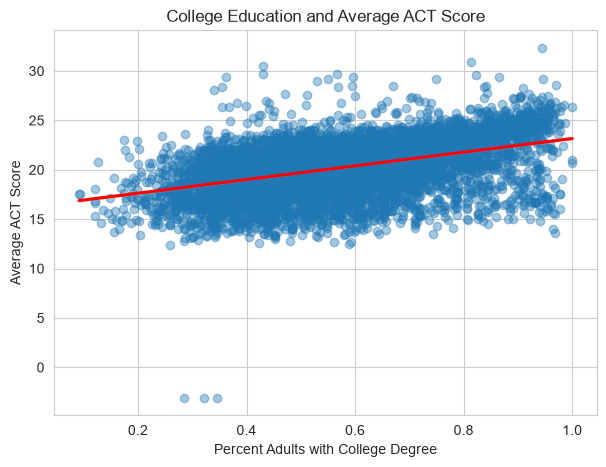

In [852]:
plt.figure(figsize=(7, 5))

sns.regplot(
    data=df,
    x='percent_college',
    y='average_act',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.xlabel('Percent Adults with College Degree')
plt.ylabel('Average ACT Score')
plt.title('College Education and Average ACT Score')

plt.show()

In [853]:
df[
    [
        'average_act',
        'percent_college',
        'median_income',
        'rate_unemployment'
    ]
].corr().round(3)

,average_act,percent_college,median_income,rate_unemployment
average_act,1.000,0.441,0.453,-0.426
percent_college,0.441,1.000,0.706,-0.409
median_income,0.453,0.706,1.000,-0.484
rate_unemployment,-0.426,-0.409,-0.484,1.000


In [854]:
model_college = smf.ols(
    formula='average_act ~ percent_college',
    data=df
).fit()

print(model_college.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.195
Model:                            OLS   Adj. R-squared:                  0.195
Method:                 Least Squares   F-statistic:                     1933.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:23:48   Log-Likelihood:                -18082.
No. Observations:                7986   AIC:                         3.617e+04
Df Residuals:                    7984   BIC:                         3.618e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          16.2458      0.093    1

In [855]:
model_personal = smf.ols(
    formula='''
    average_act ~ percent_college
                + median_income
                + rate_unemployment
    ''',
    data=df
).fit()

print(model_personal.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     1048.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:23:48   Log-Likelihood:                -17621.
No. Observations:                7986   AIC:                         3.525e+04
Df Residuals:                    7982   BIC:                         3.528e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            18.3928      0.12

In [856]:
model_personal.params.round(4)

Intercept            18.3928
percent_college       3.2744
median_income         0.0000
rate_unemployment   -11.0940
dtype: float64

In [857]:
model_personal.pvalues.round(4)

Intercept            0.0
percent_college      0.0
median_income        0.0
rate_unemployment    0.0
dtype: float64

In [858]:
model_personal.conf_int().round(4)

,0,1
Intercept,18.1534,18.6322
percent_college,2.8604,3.6883
median_income,0.0000,0.0000
rate_unemployment,-12.0351,-10.1528


In [859]:
comparison = pd.DataFrame({
    'R-squared': [
        model_college.rsquared,
        model_personal.rsquared
    ],
    'Adjusted R-squared': [
        model_college.rsquared_adj,
        model_personal.rsquared_adj
    ]
},
index=[
    'College only',
    'College + Income + Unemployment'
])

comparison.round(4)

,R-squared,Adjusted R-squared
College only,0.1949,0.1948
College + Income + Unemployment,0.2826,0.2823


In [860]:
from sklearn.metrics import mean_absolute_error

mae_college = mean_absolute_error(
    df['average_act'],
    model_college.predict()
)

mae_personal = mean_absolute_error(
    df['average_act'],
    model_personal.predict()
)

pd.DataFrame({
    'Mean Absolute Error': [
        mae_college,
        mae_personal
    ],
    'R-squared': [
        model_college.rsquared,
        model_personal.rsquared
    ]
},
index=[
    'College only',
    'College + Income + Unemployment'
]).round(4)

,Mean Absolute Error,R-squared
College only,1.7798,0.1949
College + Income + Unemployment,1.6484,0.2826


In [861]:
print(
    "College coefficient - simple model:",
    model_college.params['percent_college']
)

print(
    "College coefficient - adjusted model:",
    model_personal.params['percent_college']
)

College coefficient - simple model: 6.918368365834917
College coefficient - adjusted model: 3.274354761736955


In [754]:
print(
    "College p-value:",
    model_personal.pvalues['percent_college']
)

College p-value: 1.904483854814031e-53


In [863]:
df['charter'].value_counts()

charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64

In [864]:
df['charter_school'] = df['charter'].map({
    'No': 0,
    'Yes': 1
})

In [865]:
df[['charter', 'charter_school']].head()

,charter,charter_school
0,Yes,1.0
1,No,0.0
2,No,0.0
3,No,0.0
4,No,0.0


In [866]:
df.groupby('charter')['average_act'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

,count,mean,median,std
charter,,,,
No,7329,20.30,20.52,2.56
Not applicable,217,19.19,19.00,1.67
Yes,352,19.06,19.10,2.93


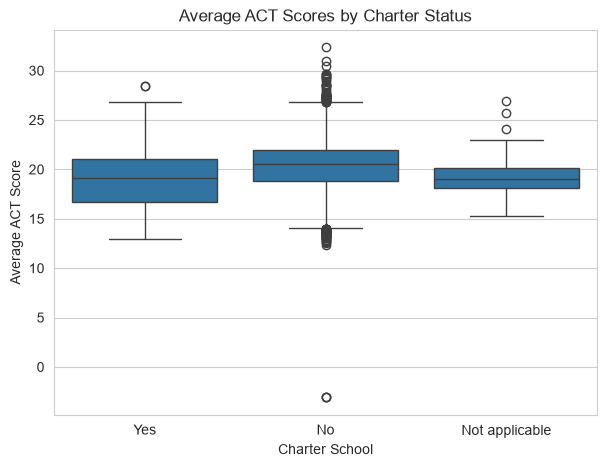

In [867]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='charter',
    y='average_act'
)

plt.xlabel('Charter School')
plt.ylabel('Average ACT Score')
plt.title('Average ACT Scores by Charter Status')

plt.show()

In [868]:
model_charter = smf.ols(
    formula='''
    average_act ~
    rate_unemployment +
    percent_college +
    percent_married +
    median_income +
    percent_lunch +
    charter_school
    ''',
    data=df
).fit()

print(model_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.605
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     1958.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:21:37   Log-Likelihood:                -14632.
No. Observations:                7681   AIC:                         2.928e+04
Df Residuals:                    7674   BIC:                         2.933e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.5809      0.14

In [869]:
print(
    "Charter school coefficient:",
    model_charter.params['charter_school']
)

print(
    "Charter school p-value:",
    model_charter.pvalues['charter_school']
)

print(
    "95% confidence interval:"
)

print(
    model_charter.conf_int().loc['charter_school']
)

Charter school coefficient: -0.1665599432935723
Charter school p-value: 0.06458324753965654
95% confidence interval:
0   -0.343201
1    0.010081
Name: charter_school, dtype: float64


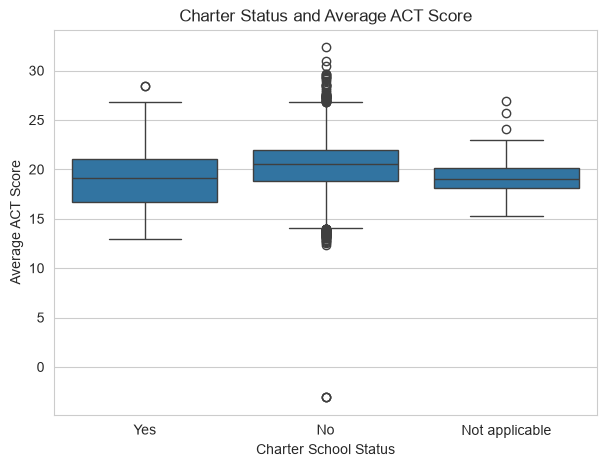

In [870]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='charter',
    y='average_act'
)

plt.xlabel('Charter School Status')
plt.ylabel('Average ACT Score')
plt.title('Charter Status and Average ACT Score')

plt.show()

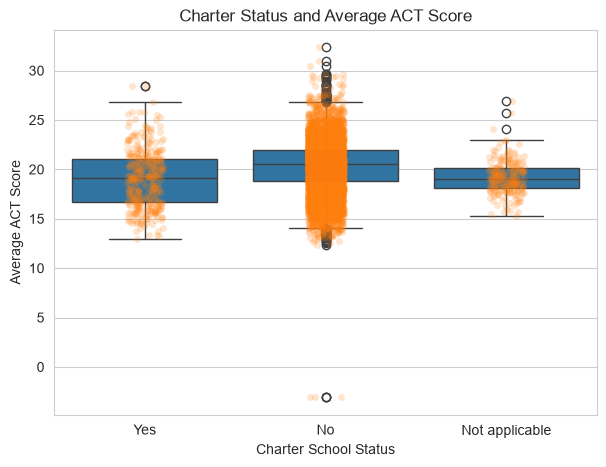

In [871]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='charter',
    y='average_act'
)

sns.stripplot(
    data=df,
    x='charter',
    y='average_act',
    alpha=0.2
)

plt.xlabel('Charter School Status')
plt.ylabel('Average ACT Score')
plt.title('Charter Status and Average ACT Score')

plt.show()

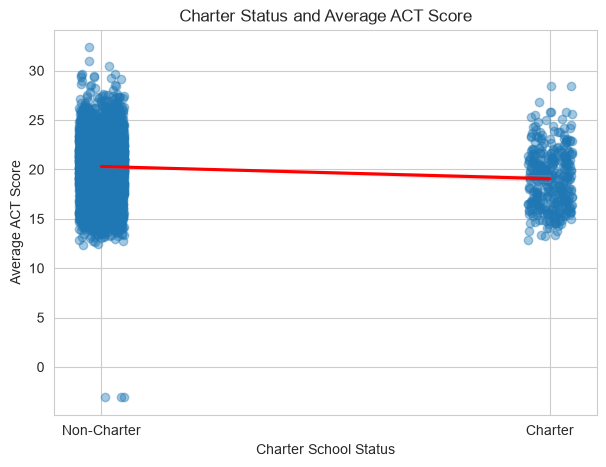

In [872]:
df['charter_school'] = df['charter'].map({
    'No': 0,
    'Yes': 1
})

plt.figure(figsize=(7, 5))

sns.regplot(
    data=df,
    x='charter_school',
    y='average_act',
    x_jitter=0.05,
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.xticks(
    [0, 1],
    ['Non-Charter', 'Charter']
)

plt.xlabel('Charter School Status')
plt.ylabel('Average ACT Score')
plt.title('Charter Status and Average ACT Score')

plt.show()

In [873]:
df.groupby('charter')['average_act'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

,count,mean,median,std
charter,,,,
No,7329,20.30,20.52,2.56
Not applicable,217,19.19,19.00,1.67
Yes,352,19.06,19.10,2.93


In [874]:
df['charter_school'] = df['charter'].map({
    'No': 0,
    'Yes': 1
})

model_charter = smf.ols(
    formula='''
    average_act ~
    rate_unemployment +
    percent_college +
    percent_married +
    median_income +
    percent_lunch +
    charter_school
    ''',
    data=df
).fit()

print(model_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.605
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     1958.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:31:43   Log-Likelihood:                -14632.
No. Observations:                7681   AIC:                         2.928e+04
Df Residuals:                    7674   BIC:                         2.933e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.5809      0.14

In [875]:
print(
    "Charter coefficient:",
    model_charter.params['charter_school']
)

print(
    "Charter p-value:",
    model_charter.pvalues['charter_school']
)

print(
    "95% confidence interval:"
)

print(
    model_charter.conf_int().loc['charter_school']
)

Charter coefficient: -0.1665599432935723
Charter p-value: 0.06458324753965654
95% confidence interval:
0   -0.343201
1    0.010081
Name: charter_school, dtype: float64


In [876]:
# 1
df['charter'].value_counts()

# 2
df.groupby('charter')['average_act'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

# 3
df['charter_school'] = df['charter'].map({
    'No': 0,
    'Yes': 1
})

# 4
# your scatter/regression plot

# 5
model_charter = smf.ols(
    formula='''
    average_act ~
    rate_unemployment +
    percent_college +
    percent_married +
    median_income +
    percent_lunch +
    charter_school
    ''',
    data=df
).fit()

print(model_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.605
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     1958.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:32:01   Log-Likelihood:                -14632.
No. Observations:                7681   AIC:                         2.928e+04
Df Residuals:                    7674   BIC:                         2.933e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.5809      0.14